<a href="https://colab.research.google.com/github/scottkeighley/skills-introduction-to-github/blob/main/adoption_case_study.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## Load Data & Inspect

In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
# --- Data Preparation ---
from google.colab import drive
drive.mount('/content/drive')

adoption = pd.read_csv('/content/drive/MyDrive/guidance_setting.csv')
print("Data are Ready!!")
print(f"Training data size is {adoption.shape}")

Mounted at /content/drive
Data are Ready!!
Training data size is (20, 17)


In [3]:
# === Basic Structure ===
print("Shape (rows, columns):", adoption.shape)
print("\nColumns:")
print(adoption.columns.tolist())

print("\nData Types:")
print(adoption.dtypes)

# === First few rows of data ===
print("\nHead:")
print(adoption.head())

# === Basic numeric summary ===
print("\nDescribe (numeric columns):")
print(adoption.describe())

Shape (rows, columns): (20, 17)

Columns:
['ID', 'JUL_2024', 'AUG_2024', 'SEP_2024', 'OCT_2024', 'NOV_2024', 'DEC_2024', 'JAN_2025', 'FEB_2025', 'MAR_2025', 'APR_2025', 'MAY_2025', 'JUN_2025', 'JUL_2025', 'AUG_2025', 'SEP_2025', 'OCT_2025']

Data Types:
ID          object
JUL_2024     int64
AUG_2024     int64
SEP_2024     int64
OCT_2024     int64
NOV_2024     int64
DEC_2024     int64
JAN_2025     int64
FEB_2025     int64
MAR_2025     int64
APR_2025     int64
MAY_2025     int64
JUN_2025     int64
JUL_2025     int64
AUG_2025     int64
SEP_2025     int64
OCT_2025     int64
dtype: object

Head:
        ID  JUL_2024  AUG_2024  SEP_2024  OCT_2024  NOV_2024  DEC_2024  \
0  CUST_01        55        55        57        51        61        69   
1  CUST_02        21        22        11        21        27        16   
2  CUST_03        27        27        25        22        15        10   
3  CUST_04        73        67        83        61        64        65   
4  CUST_05        34        33  

## Notes:

#### Mean trends over time
| Month | Mean |
| --- | --- |
| JUL_2024 | 46.8 |
| OCT_2024 | 48.2 |
| JAN_2025 | 48.8 |
| JUN_2025 | 51.8 |
| OCT_2025 | 53.3 |

On average, adoption is slowly rising over time. "Default world" for adoption isn't flat or collapsing.

#### Spread / Outliers
Later months:
- Std dev ~27-31 -> wide spread
- Min = 0 in several months -> some customers are unengaged
- Max = 100 in several months -> some customers are capped

Implications:
- customers already near 100 don't have much headroom; aggressive uplift targets may be unrealistic
- Customers near 0 could, in theory, move a lot. In practice, it may be harder to move (new or early life-cycle). We'll need to think about baseline bands

Should treat this as a target-setting & calibration problem, using simple statistical summaries and trends. Build core methodology around:
- Historical 3-month uplift distributions
- Baseline score bands
- Map targets and expected attainment distribution

## EDA

In [4]:
import calendar

# === List month columns ===
month_cols = [c for c in adoption.columns if c != 'ID']
print("Month columns:", month_cols)

Month columns: ['JUL_2024', 'AUG_2024', 'SEP_2024', 'OCT_2024', 'NOV_2024', 'DEC_2024', 'JAN_2025', 'FEB_2025', 'MAR_2025', 'APR_2025', 'MAY_2025', 'JUN_2025', 'JUL_2025', 'AUG_2025', 'SEP_2025', 'OCT_2025']


In [5]:
# === Melt to long format: one row per ID, month_label ===
adoption_long = adoption.melt(
    id_vars="ID",
    value_vars=month_cols,
    var_name="month_label",
    value_name="score"
)

print("\nLong forma head:")
print(adoption_long.head())


Long forma head:
        ID month_label  score
0  CUST_01    JUL_2024     55
1  CUST_02    JUL_2024     21
2  CUST_03    JUL_2024     27
3  CUST_04    JUL_2024     73
4  CUST_05    JUL_2024     34


In [6]:
# === Convert month_label like 'JUL_2024' to '2024-07-01' ===
def parse_month_label(label: str) -> str:
  mon_abbr, year = label.split("_")
  mon_abbr_cap = mon_abbr.capitalize()
  month_num = list(calendar.month_abbr).index(mon_abbr_cap)
  return f"{year}-{month_num:02d}-01"

adoption_long["month"] = pd.to_datetime(
    adoption_long["month_label"].apply(parse_month_label)
)

In [7]:
# === Sort by ID, then month ===
adoption_long = adoption_long.sort_values(["ID", "month"]).reset_index(drop=True)

print("\nLong format with parsed month:")
print(adoption_long.head(10))


Long format with parsed month:
        ID month_label  score      month
0  CUST_01    JUL_2024     55 2024-07-01
1  CUST_01    AUG_2024     55 2024-08-01
2  CUST_01    SEP_2024     57 2024-09-01
3  CUST_01    OCT_2024     51 2024-10-01
4  CUST_01    NOV_2024     61 2024-11-01
5  CUST_01    DEC_2024     69 2024-12-01
6  CUST_01    JAN_2025     80 2025-01-01
7  CUST_01    FEB_2025     71 2025-02-01
8  CUST_01    MAR_2025     72 2025-03-01
9  CUST_01    APR_2025     71 2025-04-01


In [8]:
# === Basic Overall trend: aggregate across customers by month ===
overall_by_month = adoption_long.groupby("month")["score"].agg(["count", "mean", "median", "min", "max"])
print("\nOverall stats by month:")
print(overall_by_month)


Overall stats by month:
            count   mean  median  min  max
month                                     
2024-07-01     20  46.75    40.0   17   77
2024-08-01     20  46.75    47.5   19   74
2024-09-01     20  49.15    47.0   11   84
2024-10-01     20  48.20    47.0   19   82
2024-11-01     20  49.20    51.0   15   84
2024-12-01     20  49.30    51.0   10   92
2025-01-01     20  48.80    53.0    4   86
2025-02-01     20  50.15    54.5   10   83
2025-03-01     20  48.55    51.0    0   95
2025-04-01     20  49.80    51.0    0   92
2025-05-01     20  49.90    53.0    3   99
2025-06-01     20  51.80    55.0    0  100
2025-07-01     20  50.65    53.0    0   94
2025-08-01     20  53.20    55.5    0  100
2025-09-01     20  51.00    53.0    0  100
2025-10-01     20  53.30    55.5    0  100


## Notes

#### Monthly trend
- Average score drifts from ~47 in mid-2024 to ~53 by Oct-2025
- Only a modest uplift (a few points over more than a year)
- Median scores are usually slighly above the mean -> few very low customers pulling the average down
- Starting around early 2025, min hits 0 and max hits 100 regularly:
  - Some customers totally disengaged
  - Some are fully maxed-out and hitting the cap

Implication for target-setting:
- Can't treat all the baselines the same:
  - Customers already at 90+ have limited headroom
  -  Customers at 0-10 might have more mathematical headroom but may be structurally harder to move
- Simple baseline-band + historical uplift approach makes sense

## Understand change per customer

In [9]:
# === Compute month-to-month deltas per customer ===
# For each customer, sort by month and compute previous month's score
adoption_long = adoption_long.sort_values(["ID", "month"]).reset_index(drop=True)

adoption_long["score_prev_1m"] = adoption_long.groupby("ID")["score"].shift(1)
adoption_long["delta_1m"] = adoption_long["score"] - adoption_long["score_prev_1m"]

print("Head with 1-month lag and delta:")
print(adoption_long.head(12))

Head with 1-month lag and delta:
         ID month_label  score      month  score_prev_1m  delta_1m
0   CUST_01    JUL_2024     55 2024-07-01            NaN       NaN
1   CUST_01    AUG_2024     55 2024-08-01           55.0       0.0
2   CUST_01    SEP_2024     57 2024-09-01           55.0       2.0
3   CUST_01    OCT_2024     51 2024-10-01           57.0      -6.0
4   CUST_01    NOV_2024     61 2024-11-01           51.0      10.0
5   CUST_01    DEC_2024     69 2024-12-01           61.0       8.0
6   CUST_01    JAN_2025     80 2025-01-01           69.0      11.0
7   CUST_01    FEB_2025     71 2025-02-01           80.0      -9.0
8   CUST_01    MAR_2025     72 2025-03-01           71.0       1.0
9   CUST_01    APR_2025     71 2025-04-01           72.0      -1.0
10  CUST_01    MAY_2025     72 2025-05-01           71.0       1.0
11  CUST_01    JUN_2025     82 2025-06-01           72.0      10.0


In [10]:
# Summary of 1-month deltas
delta_summary = adoption_long["delta_1m"].describe()
print("\nOverall 1-month delta summary:")
print(delta_summary)


Overall 1-month delta summary:
count    300.000000
mean       0.436667
std        6.856825
min      -22.000000
25%       -4.000000
50%        0.000000
75%        5.000000
max       19.000000
Name: delta_1m, dtype: float64


In [11]:
# How often do we see improvements vs declines vs flat?
improve = (adoption_long["delta_1m"] > 0).sum()
decline = (adoption_long["delta_1m"] < 0).sum()
flat = (adoption_long["delta_1m"] == 0).sum()

print("\nCounts of 1-month movement:")
print("Improved :", improve)
print("Declined :", decline)
print("No change :", flat)


Counts of 1-month movement:
Improved : 142
Declined : 129
No change : 29


## Notes

#### Distribution
- mean = +0.44 -> on average, customers gain less than half a point per month
- std = 6.86 -> month-to-month moves are very noisy
- min = -22, max = +19 -> individual customers can swing 20+ points up or down in a single month
- Quartiles:
  - 25%: -4
  - 50%: 0
  - 75%: +5

In any given month, a typical customer is just as likely to go up or down by a few points, and large swings (+- 10 or more) are not rare. There is a slight upward drift over time, but the short-term noise is big relative to the average improvement.

#### Up vs down vs flat
Almost 50/50 between improvement and decline

Month over month, scores are quite volatile: in about half of months, scores go up; in the other half, they go down. The typical net monthly improvement is small relative to the random variation.

#### Next 3-month deltas
Real business window is Oct 2025 -> Jan 2026:
- Look at historical 3-month changes
- Use that distribution to design a target methodology

In [12]:
# === Compute 3-month lead and delta per customer ===
# Create a 3-month-ahead score for each customer
adoption_long["score_plus_3m"] = adoption_long.groupby("ID")["score"].shift(-3)

In [13]:
# Compute 3-month delta
adoption_long["delta_3m"] = adoption_long["score_plus_3m"] - adoption_long["score"]

print("Head with 3-month lead and delta:")
print(adoption_long.head(15))

Head with 3-month lead and delta:
         ID month_label  score      month  score_prev_1m  delta_1m  \
0   CUST_01    JUL_2024     55 2024-07-01            NaN       NaN   
1   CUST_01    AUG_2024     55 2024-08-01           55.0       0.0   
2   CUST_01    SEP_2024     57 2024-09-01           55.0       2.0   
3   CUST_01    OCT_2024     51 2024-10-01           57.0      -6.0   
4   CUST_01    NOV_2024     61 2024-11-01           51.0      10.0   
5   CUST_01    DEC_2024     69 2024-12-01           61.0       8.0   
6   CUST_01    JAN_2025     80 2025-01-01           69.0      11.0   
7   CUST_01    FEB_2025     71 2025-02-01           80.0      -9.0   
8   CUST_01    MAR_2025     72 2025-03-01           71.0       1.0   
9   CUST_01    APR_2025     71 2025-04-01           72.0      -1.0   
10  CUST_01    MAY_2025     72 2025-05-01           71.0       1.0   
11  CUST_01    JUN_2025     82 2025-06-01           72.0      10.0   
12  CUST_01    JUL_2025     80 2025-07-01           82.0

In [14]:
# Summary of 3-month deltas (only where we have a full 3-month window)
delta_3m_valid = adoption_long["delta_3m"].dropna()
delta_3m_summary = delta_3m_valid.describe()

print("\nOverall 3-month delta summary:")
print(delta_3m_summary)


Overall 3-month delta summary:
count    260.000000
mean       1.142308
std        8.456506
min      -19.000000
25%       -5.000000
50%        1.000000
75%        7.000000
max       29.000000
Name: delta_3m, dtype: float64


In [15]:
# Counts of improvement / decline / flat over 3 months
improve_3m = (delta_3m_valid > 0).sum()
decline_3m = (delta_3m_valid < 0).sum()
flat_3m = (delta_3m_valid == 0).sum()

print("\nCounts of 3-month movement:")
print("Improved :", improve_3m)
print("Declined :", decline_3m)
print("No change:", flat_3m)


Counts of 3-month movement:
Improved : 137
Declined : 110
No change: 13


## Notes

#### Interpretation
Over 3 months:
- Average change = +1.1 points - very small net improvement
- Noise is large: std = 8.5, with swings from -19 to +29
- Typical range:
  - 25% of 3-month periods are worse than -5 points
  - 50% is +1
  - 75% is +7 -> hitting +7 over 3 months is good but not huge
- Slight skew toward improvement (137 improved vs 110 declined), but declines are still common

Looking at 3-month windows, customers typically move only a point or two, but it's common to see swings of 5-10 points up or down. A strong 3-month improvement might be around +7, while very big jumps above +10 or drops below -10 are rare but do happen.

#### Next step: 3-month uplift by starting score band
Right now, delta_3m is unconditional. But targets need to respect baseline
- A customer starting at 20 has more headroom than one starting at 90
- A 10-point uplift from 20 -> 30 is different from 90 -> 100

Steps:
- Take all valid 3-month windows (where score_plus_3m isn't NaN)
- Bucket the starting score into baseline bands
- Look at the distribution of 3-month deltas within each band

In [16]:
# === Band the starting scores and summarize deltas ===
# Keep only rows where we have a full 3-month window
three_month = adoption_long.dropna(subset=["score_plus_3m"]).copy()

In [17]:
# Define baseline score bands
bins = [0, 30, 60, 80, 100]
labels = ["0-30", "30-60", "60-80", "80-100"]

three_month["start_band"] = pd.cut(
    three_month["score"],
    bins=bins,
    labels=labels,
    include_lowest=True,
    right=True
)

print("Counts by starting band:")
print(three_month["start_band"].value_counts(dropna=False))

Counts by starting band:
start_band
30-60     87
60-80     84
0-30      71
80-100    18
Name: count, dtype: int64


In [18]:
# Summary of 3-month deltas per band
band_stats = three_month.groupby("start_band")["delta_3m"].describe(
    percentiles=[0.25, 0.5, 0.75, 0.9]
)

print("\n3-month delta distribution by starting band:")
print(band_stats)


3-month delta distribution by starting band:
            count      mean       std   min  25%  50%   75%   90%   max
start_band                                                             
0-30         71.0 -1.422535  8.139256 -18.0 -7.0 -1.0  4.50  10.0  18.0
30-60        87.0  3.103448  8.523612 -19.0 -4.0  4.0  8.00  12.0  29.0
60-80        84.0  1.238095  8.209044 -17.0 -5.0  1.5  7.25  11.7  18.0
80-100       18.0  1.333333  8.540561 -18.0 -2.5  1.5  5.75  11.8  16.0


/tmp/ipython-input-3656602024.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  band_stats = three_month.groupby("start_band")["delta_3m"].describe(


## Notes

#### What the banded 3-month deltas say
- 0-30 band:
  - On average, these customers slightly decline over 3 months (mean = -1.4)
  - Typical range: -7 to +4.5 (25-75%)
  - A really strong 3-month improvement here is +10 or more
- 30-60 band:
  - Most "improvable" customers: mean +3.1, median +4
  - 75th percentile uplift = +8 -> strong 3-month improvement is around +8
  - 90th = +12 -> top decile performance
- 60-80 band:
  - Smaller net improvement: mean +1.2, median +1.5
  - 75th percentils = +7.25 -> strong, but a bit lower than 30-60
- 80-100 band:
  - Headroom is limited: mean +1.3, median +1.5, 75th = +5.75
  - We see +10+ jumps, but those are rare and partially constrained by the cap at 100

Customers in the middle (30-60) typically show the biggest three-month improvements. Very low and very high customers are harder to move: low scores often slip or only improve a little, and high scores have limited headroom because they're close to 100.

#### Target-setting rule
(A) Use October 2025 as baseline and band customers
- For each customer, take OCT_2025 as baseline_score
- Place them into the same bands

(B) For each band, choose a "stretch percentile" of 3-month uplift
- For 0-30: target upfligt = 75th percentile of deltas in this band -> +4.5 points (round to +5)
- For 30-60: 75th percentile = +8
- For 60-80: 75th percentile = +7.25 (round to +7)
- For 80-100: 75th percentile = +5.75 (round to +6)

For each baseline band, we set the target uplift roughly at the 75th percentile of historical three-month improvements for similar customers. That means we're asking managers to land closer to the top quartile of historical performance for each type of customer.

(C) Translate uplfit into target score
For each customer:
- target_uplift = uplift_for_band(baseline_band)
- raw_target_score = baseline_score + target_uplift
- Because scores are capped at 100:
  - target_score = min(raw_target_score, 100)

(D) Expected attainment
- If we assume that future 3-month changes will resemble historical 3-month changes, then:
  - A customer in a given band has:
    - a random 3-month change delta_3m drawn form the historical distribution for that band
    - a target uplift U_band (75th percentile)
- Within each band:
  - Use the 75th percentile uplift as U_band:
    - About 25% of historical deltas are above U_band, so those would achive >100% attainment
    - The median delta (1-4 points depending on band) translates to ~20-60% attainment
  - When we weight by the actual mix of customers across bands, we'll get the overall expected attainment distribution

Expected attainment is just historical 3-month uplift scaled by the chosen target uplift. By picking the uplift at a certain percentile (75th), we control what fraction of managers are expected to exceed 100% if performance looks like hisotry.

In [19]:
# === Compute per-band uplift from data & assign targets ===
# Choose the percentile
target_percentile = 0.75

uplift_by_band = (
    three_month
    .groupby("start_band")["delta_3m"]
    .quantile(target_percentile)
    .rename("target_uplift_raw")
    .to_frame()
)

print("Raw uplift (75th percentile) by band:")
print(uplift_by_band)

Raw uplift (75th percentile) by band:
            target_uplift_raw
start_band                   
0-30                     4.50
30-60                    8.00
60-80                    7.25
80-100                   5.75


/tmp/ipython-input-3202600851.py:7: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("start_band")["delta_3m"]


In [20]:
# Round to whole numbers
uplift_by_band["target_uplift"] = uplift_by_band["target_uplift_raw"].round().astype(int)

print("\nRounded target uplifts by band:")
print(uplift_by_band)


Rounded target uplifts by band:
            target_uplift_raw  target_uplift
start_band                                  
0-30                     4.50              4
30-60                    8.00              8
60-80                    7.25              7
80-100                   5.75              6


In [21]:
# === Assign bands and targets to October 2025 baselines ===
# Extract October 2025 baselines
oct_2025 = adoption[["ID", "OCT_2025"]].copy()
oct_2025 = oct_2025.rename(columns={"OCT_2025": "baseline_score"})

In [22]:
# Band the baseline scores using the same bins/labels
bins = [0, 30, 60, 80, 100]
labels = ["0-30", "30-60", "60-80", "80-100"]

oct_2025["baseline_band"] = pd.cut(
    oct_2025["baseline_score"],
    bins=bins,
    labels=labels,
    include_lowest=True,
    right=True
)

print("October 2025 baselines with bands:")
print(oct_2025)

October 2025 baselines with bands:
         ID  baseline_score baseline_band
0   CUST_01              83        80-100
1   CUST_02               0          0-30
2   CUST_03               0          0-30
3   CUST_04              64         60-80
4   CUST_05              46         30-60
5   CUST_06              65         60-80
6   CUST_07             100        80-100
7   CUST_08              55         30-60
8   CUST_09              70         60-80
9   CUST_10              15          0-30
10  CUST_11             100        80-100
11  CUST_12              44         30-60
12  CUST_13               0          0-30
13  CUST_14              48         30-60
14  CUST_15              80         60-80
15  CUST_16              81        80-100
16  CUST_17              56         30-60
17  CUST_18              78         60-80
18  CUST_19              26          0-30
19  CUST_20              55         30-60


In [23]:
# Join with uplift_by_band to get per-customer target uplift
targets = oct_2025.merge(
    uplift_by_band[["target_uplift"]],
    left_on="baseline_band",
    right_index=True,
    how="left"
)

In [24]:
# Compute target scores, capping at 100
targets["raw_target_score"] = targets["baseline_score"] + targets["target_uplift"]
targets["target_score"] = targets["raw_target_score"].clip(upper=100)

print("\nPer-customer baseline and target:")
print(targets)


Per-customer baseline and target:
         ID  baseline_score baseline_band  target_uplift  raw_target_score  \
0   CUST_01              83        80-100              6                89   
1   CUST_02               0          0-30              4                 4   
2   CUST_03               0          0-30              4                 4   
3   CUST_04              64         60-80              7                71   
4   CUST_05              46         30-60              8                54   
5   CUST_06              65         60-80              7                72   
6   CUST_07             100        80-100              6               106   
7   CUST_08              55         30-60              8                63   
8   CUST_09              70         60-80              7                77   
9   CUST_10              15          0-30              4                19   
10  CUST_11             100        80-100              6               106   
11  CUST_12              44  

## Notes

#### Sanity check
uplift_by_band:
- 0-30 -> target uplift = 4 points
- 30-60 -> target uplift = 8 points
- 60-80 -> target uplift = 7 points
- 80-100 -> target uplift = 6 points

Sample customer targets:
- CUST_01: baselines 83 -> band 80-100 -> target = 89
- CUST_02: baseline 0 -> band 0-30 -> target = 4
- CUST_05: baseline 46 -> band 30-60 -> target = 54
- CUST_07: baseline 100 -> band 80-100 -> raw target 106, capped at 100

We take each customer's October score as a baseline. We place them into a band based on that score and then add a band-specific uplift that corresponds roughly to the 75th percentile of historical three-month improvements for similar customers. High-baseline customers get smaller uplifts (less headroom); mid-range customers get bigger uplifts (most improvable). We cap all scores at 100

## Formalized proposed methodology

#### Step 1 - Baseline and segmentation
- Use October 2025 score as the baseline for each customer
- Segment customers into bands by baseline score:
  - 0-30, 30-60, 60-80, 80-100

#### Step 2 - Historical uplift by band
- For each cusotmer and month, compute the 3-month change in adoption:
$$\Delta_{3m} = Score_{t+3m} - Score_t$$
- Group these 3-month deltas by the starting band of the customer
- For each band, estimate the distribution of 3-month uplift (mean, median, quartiles, 75th, 90th percentiles, etc.)

#### Step 3 - Target uplift per band
- For each band, set the target uplift to approximately the 75th percentile of historical 3-month uplift in that band
  - 0-30 -> +4 points
  - 30-60 -> +8 points
  - 60-80 -> +7 points
  - 80-100 -> +6 points

We ask CSMs to deliver a three-month improvement that's roughly at the 75th percentile of what similar customers have actually achieved in the past. That's a stretch, but grounded in historical performance.

#### Step 4 - Target score for January 2026
For each customer:
- target_score_raw = baseline_score + target_uplift_band
- target_score = min(target_score_raw, 100) (capped at 100)

#### Step 5 - Assumptions
- The relationship between baseline and uplift is similar going forward (no major product or process shock)
- The mix of customer types (segments, stages) is roughly stable
- Adoption scores are measured consistently and meaningfully (no big scoring logic changes)
- CSM influence on adoption is not radically changing between the historical period and Oct 2025 - Jan 2025

In [25]:
# === Compute simulated attainment per historical 3-month window
# Attach target uplift to each historical 3-month window
three_month_att = three_month.merge(
    uplift_by_band[["target_uplift"]],
    left_on="start_band",
    right_index=True,
    how="left"
)

In [26]:
# Compute simulated attainment for each window
# attainment_sim = actual 3m uplift / target uplift for that band
three_month_att["attainment_sim"] = (
    three_month_att["delta_3m"] / three_month_att["target_uplift"]
)

print("Attainment simulation head:")
print(three_month_att[["ID", "score", "start_band", "delta_3m", "target_uplift", "attainment_sim"]].head())

Attainment simulation head:
        ID  score start_band  delta_3m  target_uplift  attainment_sim
0  CUST_01     55      30-60      -4.0              8       -0.500000
1  CUST_01     55      30-60       6.0              8        0.750000
2  CUST_01     57      30-60      12.0              8        1.500000
3  CUST_01     51      30-60      29.0              8        3.625000
4  CUST_01     61      60-80      10.0              7        1.428571


In [27]:
# Overall attainment distribution
print("\nOverall attainment distribution (simulated):")
print(three_month_att["attainment_sim"].describe())


Overall attainment distribution (simulated):
count    260.000000
mean       0.105220
std        1.468802
min       -4.500000
25%       -0.750000
50%        0.142857
75%        1.000000
max        4.500000
Name: attainment_sim, dtype: float64


In [28]:
# Bucket the attainment for easier interpretation
bins = [-999, 0, 0.5, 0.8, 1.0, 1.2, 1.5, 999]
labels = ["<=0", "0-50%", "50-80%", "80-100%", "100-120%", "120-150%", ">150%"]

three_month_att["attainment_bucket"] = pd.cut(
    three_month_att["attainment_sim"],
    bins=bins,
    labels=labels
)

print("\nCounts by attainment bucket (simulated):")
print(three_month_att["attainment_bucket"].value_counts().sort_index())


Counts by attainment bucket (simulated):
attainment_bucket
<=0         123
0-50%        38
50-80%       18
80-100%      19
100-120%      5
120-150%     22
>150%        35
Name: count, dtype: int64


## Notes

#### High-level statistics
- median attainment is ~14%, not near 100%
- 25% of historical windows are below ~75% attainment
- 75% of windows are below 100% attainment
- Attainment fluctuates wildly (std. ~1.47)
- There are many extreme negative and positive outliers

#### Bucketed distribution
Almost half of historical 3-month periods would produce negative attainment under this target approach. Only about 9 out of 260 (7%) would land in the 80-100% range. Very few (2%) would score between 100-120%. A surprisingly large chunk (~22% + 13% = ~35%) would land well over 120%, because a few 3-month windows had very large positive swings relative to the target uplift

#### Visual summary:
- Left tail: very large. 123/260 (~47%) <= 0%
- Middle: thin. Only 75 or so windows (~29%) are in the 0-100% range
- Right tail: moderate. ~22% exceed 120%

Very far from a bell curve

## Why this happened
Root cause is the underlying data generating process

#### Insight 1 - month-to-month volatility is huge
- 1m deltas: std ~6.9
- 3m deltas: std ~8.5
- Max +29, min -19 in just 3 months

This behavior makes attainment inherently chaotic if we set deterministic point targets

#### Insight 2 - targets are fixed within bands
Used:
- 0-30 -> +4
- 30-60 -> +8
- 60-80 -> +7
- 80-100 -> +6

But the variance within bands is large - some customers move +10, some -10. Any fixed target uplift per band will create huge spread in attainment

#### Insight 3 - 75th percentile uplift creates a natural bias
If we choose a target = 75th percentile uplift:
- 75th percentile -> by definition, 25% of historical windows exceed the target uplift
- BUT because deltas have long positive and negative tails, behavior is not symmetric around the percentiles -> the attainment distribution becomes long-tailed

#### What this means
If we set targets at ~75th percentile of historical 3-month improvement for each band, we would expect the majority of customers - roughly half - to fall below 0% attainment and only a small fraction to land near 100%. Meanwhile, a non-trivial upper tail would exceed 150% attianment because of occasional large 3-month jumps.

The distribution is not bell-shaped. It is highly skewed, with a heavy left tail and a long right tail. This reflects the underlying volatility of adoption scores.

This shows:
- Why pure uplift-based point targets won't yield a normal distribution
- Why simple time-series forecasting won't resolve this either
- Why the "normalization" must be explicitely designed - not derived naturally

## How to normalize the distribution

#### Option A - Reduce the target percentile
The simplest way to move our attainment distribution toward a bell curve is:
- Use lower percentiles for target uplift:
  - 60th or 65th instead of 75th
  - Possibly 50th or 55th for the 0-30 and 80-100 bands (where variance is huge)
- Why this works:
  - Lower targets -> fewer negatives -> larger central mass
  - Smaller target uplift -> more windows fall near 80-120% attainment
  - Put the left tail rightward and compress extreme positive attainment

#### Option B - Use band-specific percentiles
Current approach uses 75th across all bands, but data suggests:
- 0-30 band is extremely noisy -> maybe use 50-60%
- 30-60 is most improvable -> but volatile -> maybe use 65-70%
- 60-80 improvements are smaller -> maybe 70%
- 80-100 band has headroom limits -> maybe 60-65%

This creates more balanced performance expectations

#### Opotion C - Add a variance adjusted target uplift
Instead of:
- target_uplift = percentile(delta_3m)

Use:
- target_uplift = a x percentile(delta_3m) + b x std_band

Where:
- a < 1 reduces stretch
- b > 0 compensates for naturally volatile customers

This can bring extreme tails inward

#### Option D - Convert to relative improvement rather than absolute points
e.g.: target = "increase by x% of headroom"

This naturally compresses extremes and yields smoother distributions

#### Option E - Directly specify the target distribution we want
Let's say leadership wants:
- 15% low performers
- 70% middle
- 15% top performers

Then we can back-solve the percentiles needed in each band to achieve it

In [29]:
# === Overall histogram of attainment ===
# attainment_sim
plt.figure(figsize=(8, 5))

<Figure size 800x500 with 0 Axes>

<Figure size 800x500 with 0 Axes>

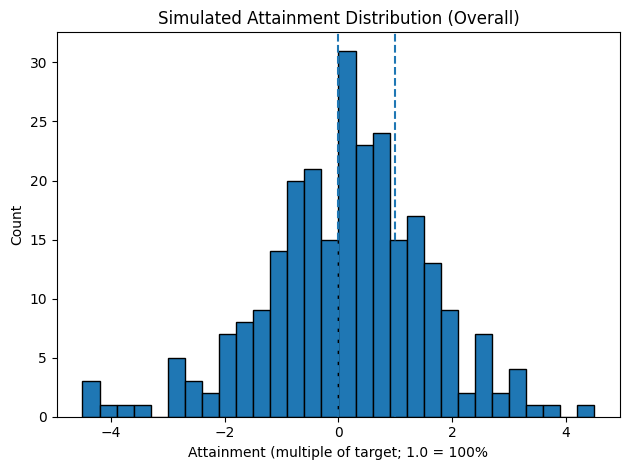

In [30]:
# Histogram
plt.hist(three_month_att["attainment_sim"], bins=30, edgecolor="black")

# Helpful reference lines at 0% and 100% attainment
plt.axvline(0.0, linestyle="--")
plt.axvline(1.0, linestyle="--")

plt.title("Simulated Attainment Distribution (Overall)")
plt.xlabel("Attainment (multiple of target; 1.0 = 100%")
plt.ylabel("Count")

plt.tight_layout()
plt.show();

## Notes
What the plot shows:
- X-axis = attainment (0 = no progress vs target, 1 = 100% of target, >1 = over achievement)
- The bulk of the bars are centered near 0, not near 1
- We added dashed lines at 0 and 1:
  - Most of the maxx is between -1.5 and +1.5, with a visible tail out beyond +-3
  - There's plenty of maxx left of 0 (negative attainment)

Statistically, we already saw:
- Median = 0.14 (14% attainment, nowhere near 100%)
- 25th percentile = -0.75
- 75th percentile = 1.0

Even though the distribution looks roughly "bell-shaped", it is centered around 0-20% attainment, not 100%. Under a 75th-percentil uplift target, the typical three-month outcome is well below target, and a large share of cases actually have negative attainment.

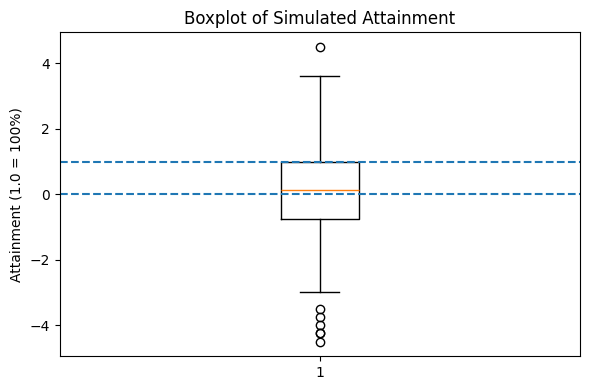

In [31]:
# === Boxplot ===
plt.figure(figsize=(6, 4))

plt.boxplot(three_month_att["attainment_sim"], vert=True)

plt.axhline(0.0, linestyle="--")
plt.axhline(1.0, linestyle="--")

plt.title("Boxplot of Simulated Attainment")
plt.ylabel("Attainment (1.0 = 100%)")

plt.tight_layout()
plt.show();

## Notes
Reinforces that targets are very aggressive:
- Median line slightly above 0
- The IQR runs from ~-0.75 up to ~1.0
  - So 25% of cases are <= -75% attainment
  - 75% of cases are <= 100% attainment
- Lots of outliers on both sides (very big negative and positive swings)

The boxplot shows that one quarter of three-month periods would deliver less than -75% attainment, and only a minority would even reach 100%. Combined with the many outliers, this tells us that adoption over three months is highly volatile, and our 75th-percentile uplift targets are stretch goals, not 'middle of the road' goals.

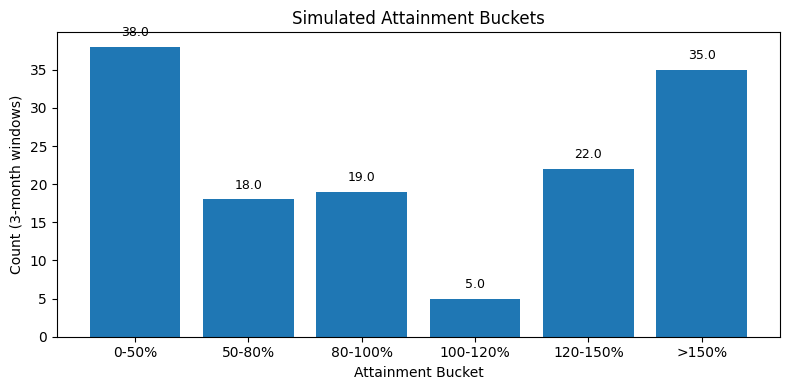

In [32]:
# === Bar chart of attainment buckets ===
# Ensure the buckets are in order
bucket_order = ["<0", "0-50%", "50-80%", "80-100%", "100-120%", "120-150%", ">150%"]

bucket_counts = (
    three_month_att["attainment_bucket"]
    .value_counts()
    .reindex(bucket_order)
)

plt.figure(figsize=(8, 4))
plt.bar(bucket_counts.index.astype(str), bucket_counts.values)

plt.title("Simulated Attainment Buckets")
plt.xlabel("Attainment Bucket")
plt.ylabel("Count (3-month windows)")

for i, v in enumerate(bucket_counts.values):
  plt.text(i, v + 1, str(v), ha="center", va="bottom", fontsize=9)

plt.tight_layout()
plt.show();

## Notes
Shows:
- Many windows in 0-50%
- Some in 50-100%
- A visible chunk above 120%

Full picture:
- A big mass at <=0% (people going backward vs target)
- Then, among the >0% cases, most in 0-50%
- Very few near 100-200%
- Meaningful tail >120-150%

If we simply set targets at the 75th percentile of historical uplift, history suggests we'd expect a large share of cases to end up at <=50% attainment, only a small fraction in the 80-120% band, and a noticeable tail of big 'overachievers' above 150%. This is not the classic "bell curve around 100%" that we might aim for.

Note: if we include at "<=0%" bar, it would be the tallest (half of all periods), further emphasizing that these targets are quite demanding.

## Overall Narrative
1. Method is grounded in data
  - Using historical 3-month uplift by baseline band and picking the 75th percentile as our stretch target. That's defensible and easy to explain.
2. But the empiracle attainment distribution is skewed and harsh
  - Centered around low attainment
  - Large share of periods below 0-50%
  - Thin band around 100%, with a tail of big winners
3. Conclusion:
  - With 75th-percentile uplift targets, we'd make targets quite aggressive: most CSMs would be below 100% in a typical three-month period, and nearly half could be at zero or negative attainment. If the business wants a more classic bell-curve around 100% attainment, weneed to lower the target percentile (e.g., to the 60-70th percentile) and possibly differentiate percentiles by band. That would shift the center of this histogram closer to 1.0 and thicken the 80-120% region

## Recompute band uplifts using the 60th percentile

In [33]:
# === 60th percentile ===
# New percentile
target_percentile_60 = 0.60

In [34]:
# 60th-percentile uplift by band
uplift_by_band_60 = (
    three_month
    .groupby("start_band")["delta_3m"]
    .quantile(target_percentile_60)
    .rename("target_uplift_raw_60")
    .to_frame()
)

print("Raw 60th-percentile uplift by band:")
print(uplift_by_band_60)

Raw 60th-percentile uplift by band:
            target_uplift_raw_60
start_band                      
0-30                         0.0
30-60                        5.6
60-80                        3.0
80-100                       3.0


/tmp/ipython-input-3758372274.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("start_band")["delta_3m"]


In [35]:
# KEY FIX: enforce minimum positive uplift of +1 point
min_uplift = 1.0

In [36]:
# Round to whole numbers
uplift_by_band_60["target_uplift_60"] = (
    np.maximum(uplift_by_band_60["target_uplift_raw_60"], min_uplift)
    .round()
    .astype(int)
)

print("\nRounded target uplifts with minimum =", min_uplift, "by band:")
print(uplift_by_band_60)


Rounded target uplifts with minimum = 1.0 by band:
            target_uplift_raw_60  target_uplift_60
start_band                                        
0-30                         0.0                 1
30-60                        5.6                 6
60-80                        3.0                 3
80-100                       3.0                 3


## Rebuilt October baseline targets using new uplifts

In [37]:
# Reuse OCT_2025 baseline table
oct_2025 = adoption[["ID", "OCT_2025"]].copy()
oct_2025 = oct_2025.rename(columns={"OCT_2025": "baseline_score"})

In [38]:
# Same bands as before
bins = [0, 30, 60, 80, 100]
labels = ["0-30", "30-60", "60-80", "80-100"]

oct_2025["baseline_band"] = pd.cut(
    oct_2025["baseline_score"],
    bins=bins,
    labels=labels,
    include_lowest=True,
    right=True
)

In [39]:
# Join the 60th percentile uplift
targets_60 = oct_2025.merge(
    uplift_by_band_60[["target_uplift_60"]],
    left_on="baseline_band",
    right_index=True,
    how="left"
)

In [40]:
# Compute new target scores for Jan 2026, cap at 100
targets_60["raw_target_score_60"] = (
    targets_60["baseline_score"] + targets_60["target_uplift_60"]
)
targets_60["target_score_60"] = targets_60["raw_target_score_60"].clip(upper=100)

print("\nPer-customer baseline and 60th-percentile targets (with min uplift):")
print(targets_60)


Per-customer baseline and 60th-percentile targets (with min uplift):
         ID  baseline_score baseline_band  target_uplift_60  \
0   CUST_01              83        80-100                 3   
1   CUST_02               0          0-30                 1   
2   CUST_03               0          0-30                 1   
3   CUST_04              64         60-80                 3   
4   CUST_05              46         30-60                 6   
5   CUST_06              65         60-80                 3   
6   CUST_07             100        80-100                 3   
7   CUST_08              55         30-60                 6   
8   CUST_09              70         60-80                 3   
9   CUST_10              15          0-30                 1   
10  CUST_11             100        80-100                 3   
11  CUST_12              44         30-60                 6   
12  CUST_13               0          0-30                 1   
13  CUST_14              48         30-60       

## Re-simulate expected attainment with 60th-percentile targets

In [41]:
# === Simulated attainment ===
# Attach 60th-percentile uplift to each historical 3-month window
three_month_att_60 = three_month.merge(
    uplift_by_band_60[["target_uplift_60"]],
    left_on="start_band",
    right_index=True,
    how="left"
)

In [42]:
# Simulated attainment under the new targets
three_month_att_60["attainment_sim_60"] = (
    three_month_att_60["delta_3m"] / three_month_att_60["target_uplift_60"]
)

print("Attainment simulation head (60th percentile targets):")
print(
    three_month_att_60[
        ["ID", "score", "start_band", "delta_3m",
         "target_uplift_60", "attainment_sim_60"]
    ].head()
)

Attainment simulation head (60th percentile targets):
        ID  score start_band  delta_3m  target_uplift_60  attainment_sim_60
0  CUST_01     55      30-60      -4.0                 6          -0.666667
1  CUST_01     55      30-60       6.0                 6           1.000000
2  CUST_01     57      30-60      12.0                 6           2.000000
3  CUST_01     51      30-60      29.0                 6           4.833333
4  CUST_01     61      60-80      10.0                 3           3.333333


In [43]:
# Overall distribution stats
print("\nOverall attainment distribution (60th percentile targets, min uplift):")
print(three_month_att_60["attainment_sim_60"].describe())


Overall attainment distribution (60th percentile targets, min uplift):
count    260.000000
mean      -0.051282
std        4.713515
min      -18.000000
25%       -1.500000
50%        0.333333
75%        1.833333
max       18.000000
Name: attainment_sim_60, dtype: float64


In [44]:
print(uplift_by_band_60)

print("\nBands with zero uplift at 60th percentile:")
print(uplift_by_band_60[uplift_by_band_60["target_uplift_60"] == 0])

            target_uplift_raw_60  target_uplift_60
start_band                                        
0-30                         0.0                 1
30-60                        5.6                 6
60-80                        3.0                 3
80-100                       3.0                 3

Bands with zero uplift at 60th percentile:
Empty DataFrame
Columns: [target_uplift_raw_60, target_uplift_60]
Index: []


In [45]:
# Bucket for readability
bins = [-999, 0, 0.5, 0.8, 1.0, 1.2, 1.5, 999]
labels = ["<=0", "0-50%", "50-80%", "80-100%", "100-120%", "120-150%", ">150%"]

three_month_att_60["attainment_bucket_60"] = pd.cut(
    three_month_att_60["attainment_sim_60"],
    bins=bins,
    labels=labels
)

print("\nCounts by attainment bucket (60th percentile targets):")
print(
    three_month_att_60["attainment_bucket_60"]
    .value_counts()
    .sort_index()
)


Counts by attainment bucket (60th percentile targets):
attainment_bucket_60
<=0         123
0-50%        17
50-80%       10
80-100%      19
100-120%      6
120-150%      9
>150%        76
Name: count, dtype: int64


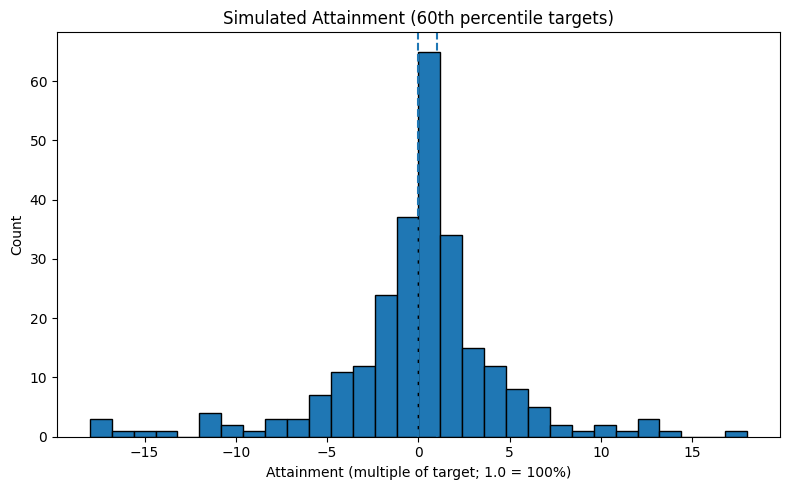

In [46]:
# Histogram
plt.figure(figsize=(8, 5))
plt.hist(three_month_att_60["attainment_sim_60"], bins=30, edgecolor="black")
plt.axvline(0.0, linestyle="--")
plt.axvline(1.0, linestyle="--")
plt.title("Simulated Attainment (60th percentile targets)")
plt.xlabel("Attainment (multiple of target; 1.0 = 100%)")
plt.ylabel("Count")
plt.tight_layout()
plt.show();

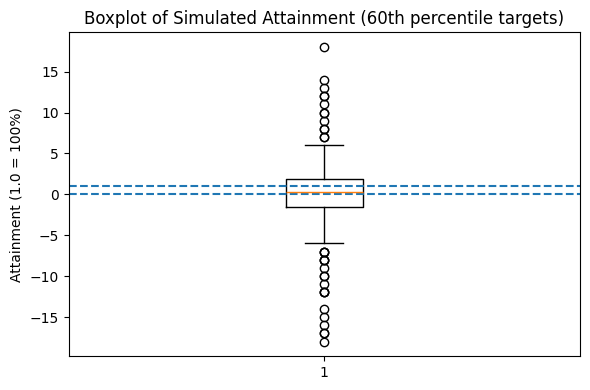

In [47]:
# Boxplot
plt.figure(figsize=(6, 4))
plt.boxplot(three_month_att_60["attainment_sim_60"], vert=True)
plt.axhline(0.0, linestyle="--")
plt.axhline(1.0, linestyle="--")
plt.title("Boxplot of Simulated Attainment (60th percentile targets)")
plt.ylabel("Attainment (1.0 = 100%)")
plt.tight_layout()
plt.show();

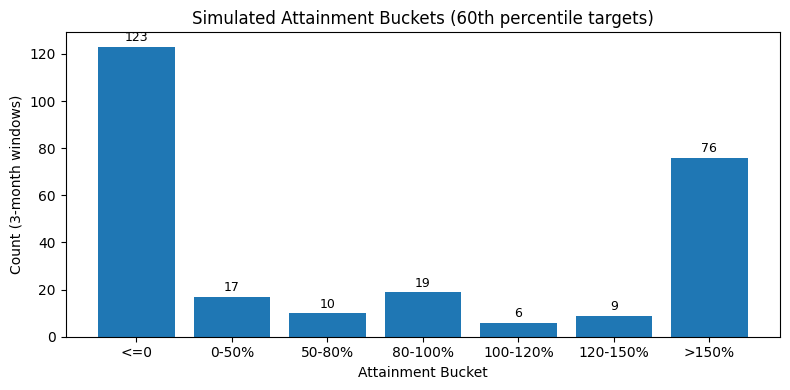

In [48]:
# Bucket bar chart
bucket_order = ["<=0", "0-50%", "50-80%", "80-100%", "100-120%", "120-150%", ">150%"]
bucket_counts_60 = (
    three_month_att_60["attainment_bucket_60"]
    .value_counts()
    .reindex(bucket_order)
)

plt.figure(figsize=(8, 4))
plt.bar(bucket_counts_60.index.astype(str), bucket_counts_60.values)
plt.title("Simulated Attainment Buckets (60th percentile targets)")
plt.xlabel("Attainment Bucket")
plt.ylabel("Count (3-month windows)")
for i, v in enumerate(bucket_counts_60.values):
    plt.text(i, v + 1, str(v), ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show();

## Notes

When we experimented iwth using the 60th percentile uplift by baseline band, we found that in some bands the historical 60th percentile was very close to zero or even negative. That would imply setting a 'target' of zero or negative improvement, which is both mathematically problematic (division by zero when computing attainment) and not meaningful as a performance goal.

To address this, we imposed a business rule that every band must have at least a +1 point uplift target. We then re-ran the attianment simulation under this adjusted rule. This keeps the methodology data-driven while ensuring targets remain positive and realistic.

#### Key points
- The share of cases <=0% attainment didn't change at all (still 123 / 260)
  - That makes sense: the sign of attainment is driven by the sign of the 3-month delta; changing the denominator doesn't change whether it's positive or negative
- The tails got much fatter, especially on the right
  - >150% went from 35 windows (75th rule) to 76 windows (60th rule)
  - Because we reduced denominators (e.g., from 8 to 6, or 7 to 3), the same big positive deltas now produce much bigger ratios
- The histogram looks evenly distributed and kind of bell-shaped, but around 0, with a massive spread, not around 1

#### Histogram
- Roughly symmetric, but:
  - It is centered close to 0, not 1
  - The horizontal axis runs from about -18 to +18 (very wide)
- The dashed lines at 0 and 1 help
  - Most mass is still clustered around 0-2x target, but there's a lot of action way out in the tails

Lowering the targets to the 60th percentile and enforcing a minimum +1 uplift doesn't give us a nice, tight bell curve around 100%. Instead, it gives us a wide, roughly symmetric distribution centered near 30-40% attainment, with very large tails because small denominators amplify the ratio.

#### Boxplot
- Median = 0.33 (still far below 100%)
- IQR from about -1.5 to +1.8
- Whiskers and outliers show deltas as large as +-18x the target

Half of outcomes fall between roughly -150% and +180% attainment, and we still see extreme wins and extreme losses. The distribution is symmetric but way too spread out and not centered on 100% attainment.

#### Bucket chart
- 123 <= 0% (same as before): lots of "no attainment or going backwards"
- Only 19 windows on 80-100%
- Only 6 in 100-120%
- A huge 76 in >150%

So, lowering the percentile:
- Didn't change how many failures we have
- Increased the number of extreme over-achievers, because smaller targets magnify big positive moves

#### How this fits the narrative
1. Initial method (75th percentile by band)
  - Data-driven, explainable
  - When we simulate attainment, the distribution is:
    - Centered slightly above 0, not 1
    - Lots of windows <=0%
    - Thin around 80-120%, some in >150%
  - Narrative: aggressive stretch targets, but not bell-shaped
2. Adjustment attempt (60th percentile + min uplift)
  - Hypothesis: "lower targets => more people near 100% => more bell-curve-ish"
  - What actually happened:
    - Sign of deltas doesn't change => still 123/260 <=0%
    - Smaller target denominators blew up big positives -> twice as many >150% outcomes
    - Distribution became wider, not tighter
  - Narrative: Simply lowering the uplift percentile does not give us the bell curve we want. It reduces the denominator in the attianment ratio, which amplifies volatility and produces more extreme over-achievement.
3. Key insight
  - Because adoption changes are inherently volatile and we measure attainment as a ratio (delta / target uplift), tweaking the percentile alone just scales the denominator. It doesn't fix the underlying asymmetry of gains vs losses, and can actually widen the attianment distribution. To shape a true 'bell curve' around 100%, we need to change either (a) the attainment formula, (b) the way we cap / clip extreme values, or (c) the band-specific percentiles in a more nuanced way, rather than just globally dropping from 75th to 60th.

#### Narrative
- Our core method (banded percentile uplift) is sound and explainable
- We then used simulation + visulaization to stress-test how different percentile choices affect attainment distribution
- The simulations showed that:
  - 75th percentile -> aggressive, skewed, not bell-shaped
  - 60th percentile -> still lots of failures, more extreme winners
- Final "normalization" recommendations:
  - Use different percentiles per band (e.g., 65% for mid, 55-60% for extremes)
  - Cap attainment at -100% and +200% before plotting / paying out
  - Define a normalized score to get closer to a bell curve:
$$z = \frac{\Delta_{3m} - \mu_{band}}{\sigma_{band}}$$

## Summary Tables

In [57]:
three_month_att["month_label"].unique()

array(['JUL_2024', 'AUG_2024', 'SEP_2024', 'OCT_2024', 'NOV_2024',
       'DEC_2024', 'JAN_2025', 'FEB_2025', 'MAR_2025', 'APR_2025',
       'MAY_2025', 'JUN_2025', 'JUL_2025'], dtype=object)

In [58]:
# === Extract actual October baseline attainment values ===
# Expected attainment under 75th percentile targets (by band)
band_att_75 = (
    three_month_att
    .dropna(subset=["attainment_sim"])
    .groupby("start_band")["attainment_sim"]
    .mean()
    .rename("expected_att_75")
    .to_frame()
)

print("Expected attainment by band (75th percentile targets):")
print(band_att_75)

Expected attainment by band (75th percentile targets):
            expected_att_75
start_band                 
0-30              -0.355634
30-60              0.387931
60-80              0.176871
80-100             0.222222


/tmp/ipython-input-2536559499.py:6: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("start_band")["attainment_sim"]


In [59]:
# Expected attainment under 60th percentile targets (by band)
band_att_60 = (
    three_month_att_60
    .dropna(subset=["attainment_sim_60"])
    .groupby("start_band")["attainment_sim_60"]
    .mean()
    .rename("expected_att_60")
    .to_frame()
)

print("\nExpected attainment by band (60th percentile targets):")
print(band_att_60)


Expected attainment by band (60th percentile targets):
            expected_att_60
start_band                 
0-30              -1.422535
30-60              0.517241
60-80              0.412698
80-100             0.444444


/tmp/ipython-input-1645777426.py:5: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("start_band")["attainment_sim_60"]


In [60]:
# 75th-percentile target table
targets_75 = targets.copy()  # if you already have 'targets' from earlier
targets_75 = targets_75.rename(columns={"target_score": "target_75"})

# 60th-percentile target table (with min uplift)
targets_60_clean = targets_60.rename(columns={"target_score_60": "target_60"})

In [61]:
# October baselines
oct_2025 = adoption[["ID", "OCT_2025"]].copy()
oct_2025 = oct_2025.rename(columns={"OCT_2025": "baseline_score"})

bins = [0, 30, 60, 80, 100]
labels = ["0-30", "30-60", "60-80", "80-100"]

oct_2025["baseline_band"] = pd.cut(
    oct_2025["baseline_score"],
    bins=bins,
    labels=labels,
    include_lowest=True,
    right=True
)

In [62]:
# 75th targets (you already computed uplift_by_band)
targets_75 = oct_2025.merge(
    uplift_by_band[["target_uplift"]],
    left_on="baseline_band",
    right_index=True,
    how="left"
)
targets_75["target_75"] = (targets_75["baseline_score"] + targets_75["target_uplift"]).clip(upper=100)

In [63]:
# 60th targets (with min uplift)
targets_60_clean = oct_2025.merge(
    uplift_by_band_60[["target_uplift_60"]],
    left_on="baseline_band",
    right_index=True,
    how="left"
)
targets_60_clean["target_60"] = (
    targets_60_clean["baseline_score"] + targets_60_clean["target_uplift_60"]
).clip(upper=100)

In [64]:
# Merge band-level expected attainment onto the 75th target table
summary = (
    targets_75[["ID", "baseline_score", "baseline_band", "target_75"]]
    .merge(band_att_75, left_on="baseline_band", right_index=True, how="left")
    .merge(
        targets_60_clean[["ID", "target_60"]],
        on="ID",
        how="left"
    )
    .merge(
        band_att_60,
        left_on="baseline_band",
        right_index=True,
        how="left"
    )
)

# Clean up column names
summary = summary.rename(
    columns={
        "expected_att_75": "attainment_75_expected",
        "expected_att_60": "attainment_60_expected"
    }
)

# Sort, round for readability
summary = summary.sort_values("ID").reset_index(drop=True)
summary["attainment_75_expected"] = summary["attainment_75_expected"].round(3)
summary["attainment_60_expected"] = summary["attainment_60_expected"].round(3)

summary

,ID,baseline_score,baseline_band,target_75,attainment_75_expected,target_60,attainment_60_expected
0,CUST_01,83,80-100,89,0.222,86,0.444
1,CUST_02,0,0-30,4,-0.356,1,-1.423
2,CUST_03,0,0-30,4,-0.356,1,-1.423
3,CUST_04,64,60-80,71,0.177,67,0.413
4,CUST_05,46,30-60,54,0.388,52,0.517
5,CUST_06,65,60-80,72,0.177,68,0.413
6,CUST_07,100,80-100,100,0.222,100,0.444
7,CUST_08,55,30-60,63,0.388,61,0.517
8,CUST_09,70,60-80,77,0.177,73,0.413
9,CUST_10,15,0-30,19,-0.356,16,-1.423
